In [1]:

from IPython.display import Audio

from scipy.io.wavfile import read

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

plt.rcParams['figure.figsize'] = (24, 10)

In [7]:
from IPython.display import Audio
import librosa

data2_1, Fs = librosa.load('data/kamhunt-sunflower-street-drumloop-85bpm-163900.mp3', sr=None)
print(f'sampling rate: {Fs}')
print(f'speaker 1 audio shape: {data2_1.shape}')
display(Audio(data2_1, rate=Fs))

data2_2, Fs = librosa.load('data/jtwayne-pianos-by-jtwayne-7-174717.mp3', sr=None)
print(f'sampling rate: {Fs}')
print(f'speaker 2 audio shape: {data2_2.shape}')
display(Audio(data2_2, rate=Fs))

data1, Fs = librosa.load('data/van_wiese-bass-wiggle-297877.mp3', sr=None)
print(f'sampling rate: {Fs}')
print(f'speaker 1 audio shape: {data1.shape}')
display(Audio(data1, rate=Fs))

sampling rate: 44100
speaker 1 audio shape: (499968,)


sampling rate: 44100
speaker 2 audio shape: (831744,)


sampling rate: 44100
speaker 1 audio shape: (324864,)


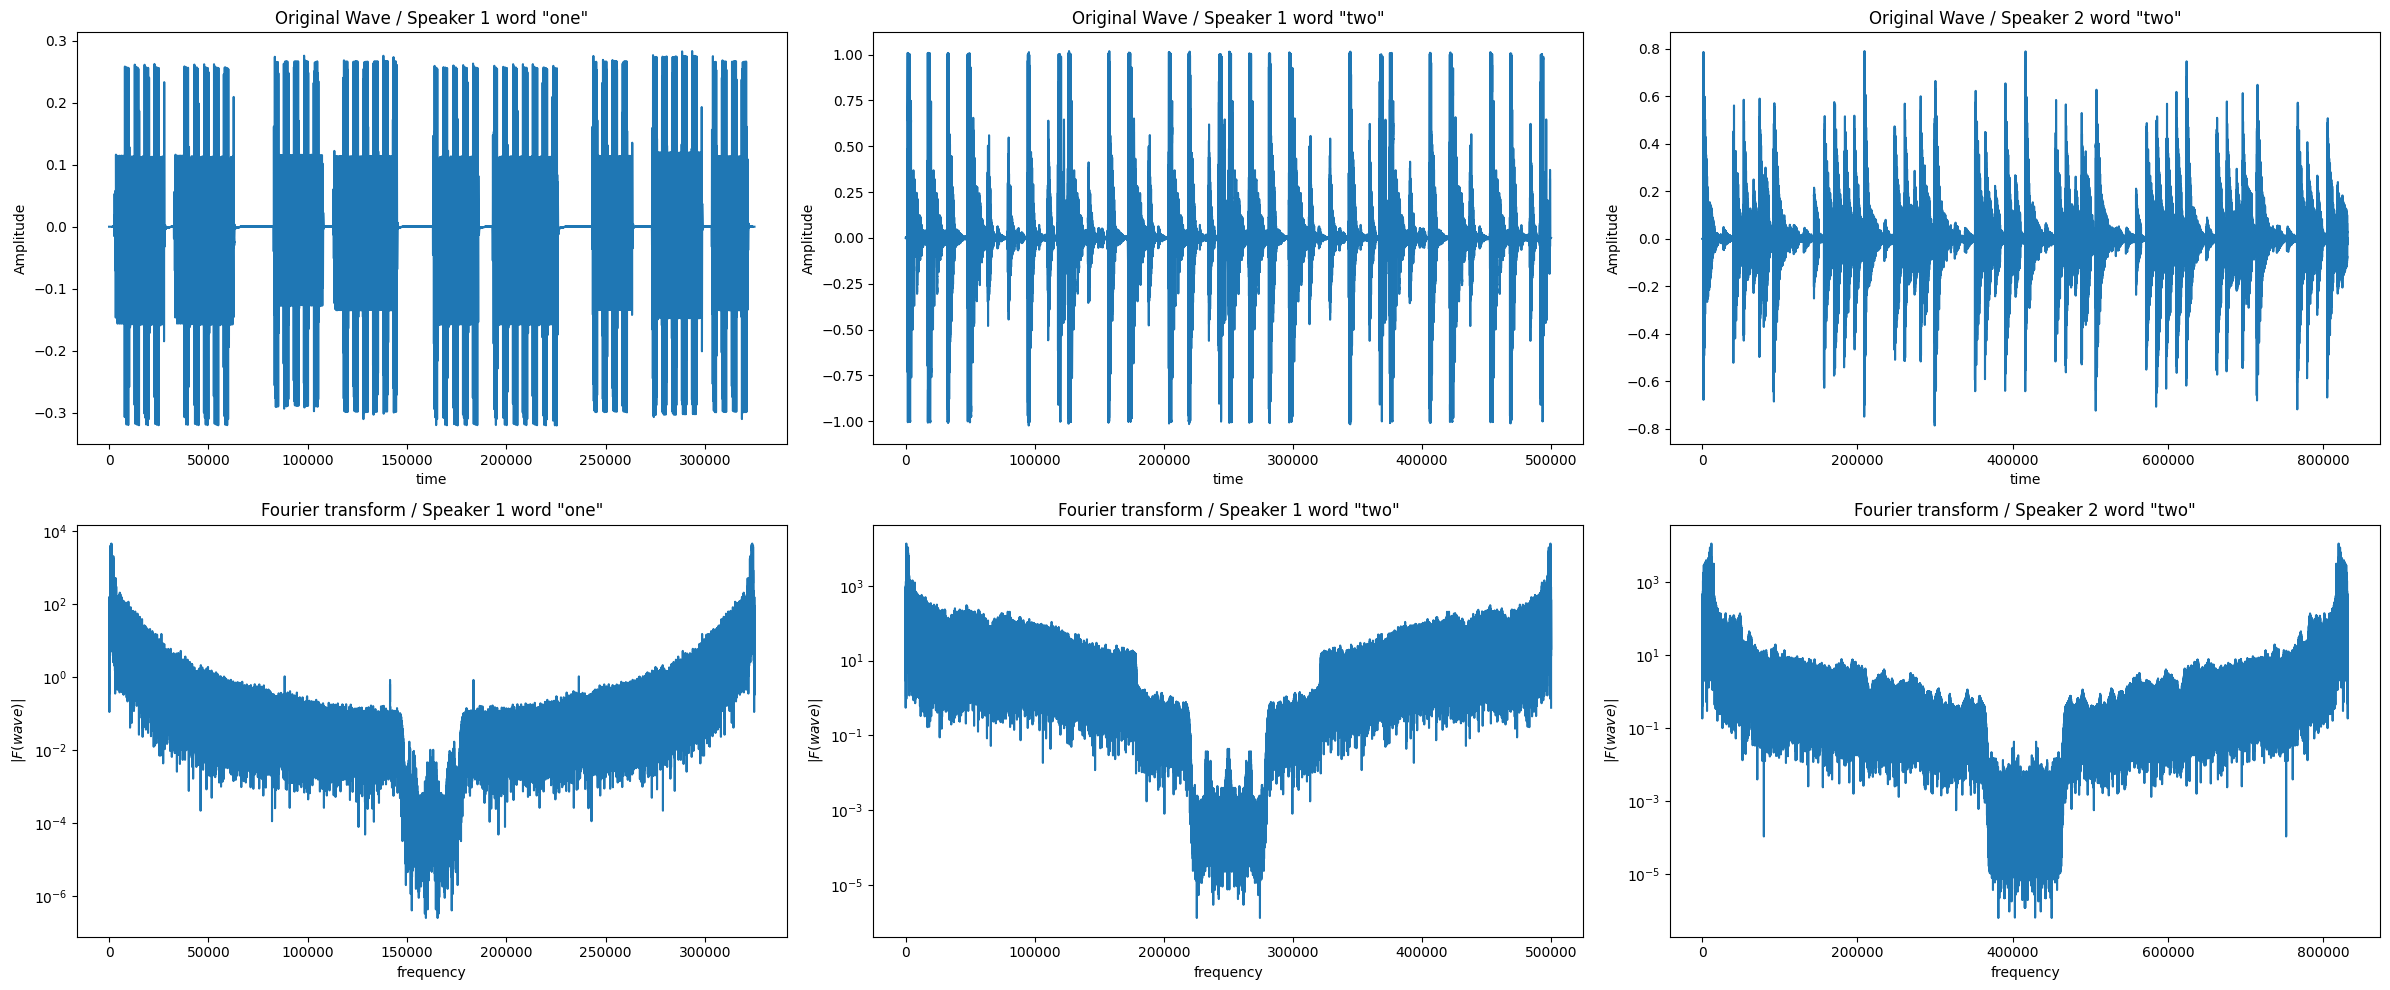

In [8]:
def plot_sound(data, axs, speaker, word):
    """
    Вспомогательная функция для построения волновой формы и её спектра Фурье.
    """
    axs[0].plot(data)
    axs[0].set_ylabel('Amplitude')
    axs[0].set_xlabel('time')
    axs[0].set_title(f'Original Wave / Speaker {speaker} word "{word}"')
    
    axs[1].semilogy(np.abs(np.fft.fft(data)))
    axs[1].set_ylabel('$| F(wave)|$')
    axs[1].set_xlabel('frequency')
    axs[1].set_title(f'Fourier transform / Speaker {speaker} word "{word}"')

fig, axs = plt.subplots(nrows=2, ncols=3)

plot_sound(data1, axs[:, 0], 1, 'one')
plot_sound(data2_1, axs[:, 1], 1, 'two')
plot_sound(data2_2, axs[:, 2], 2, 'two')

plt.tight_layout()
plt.show()

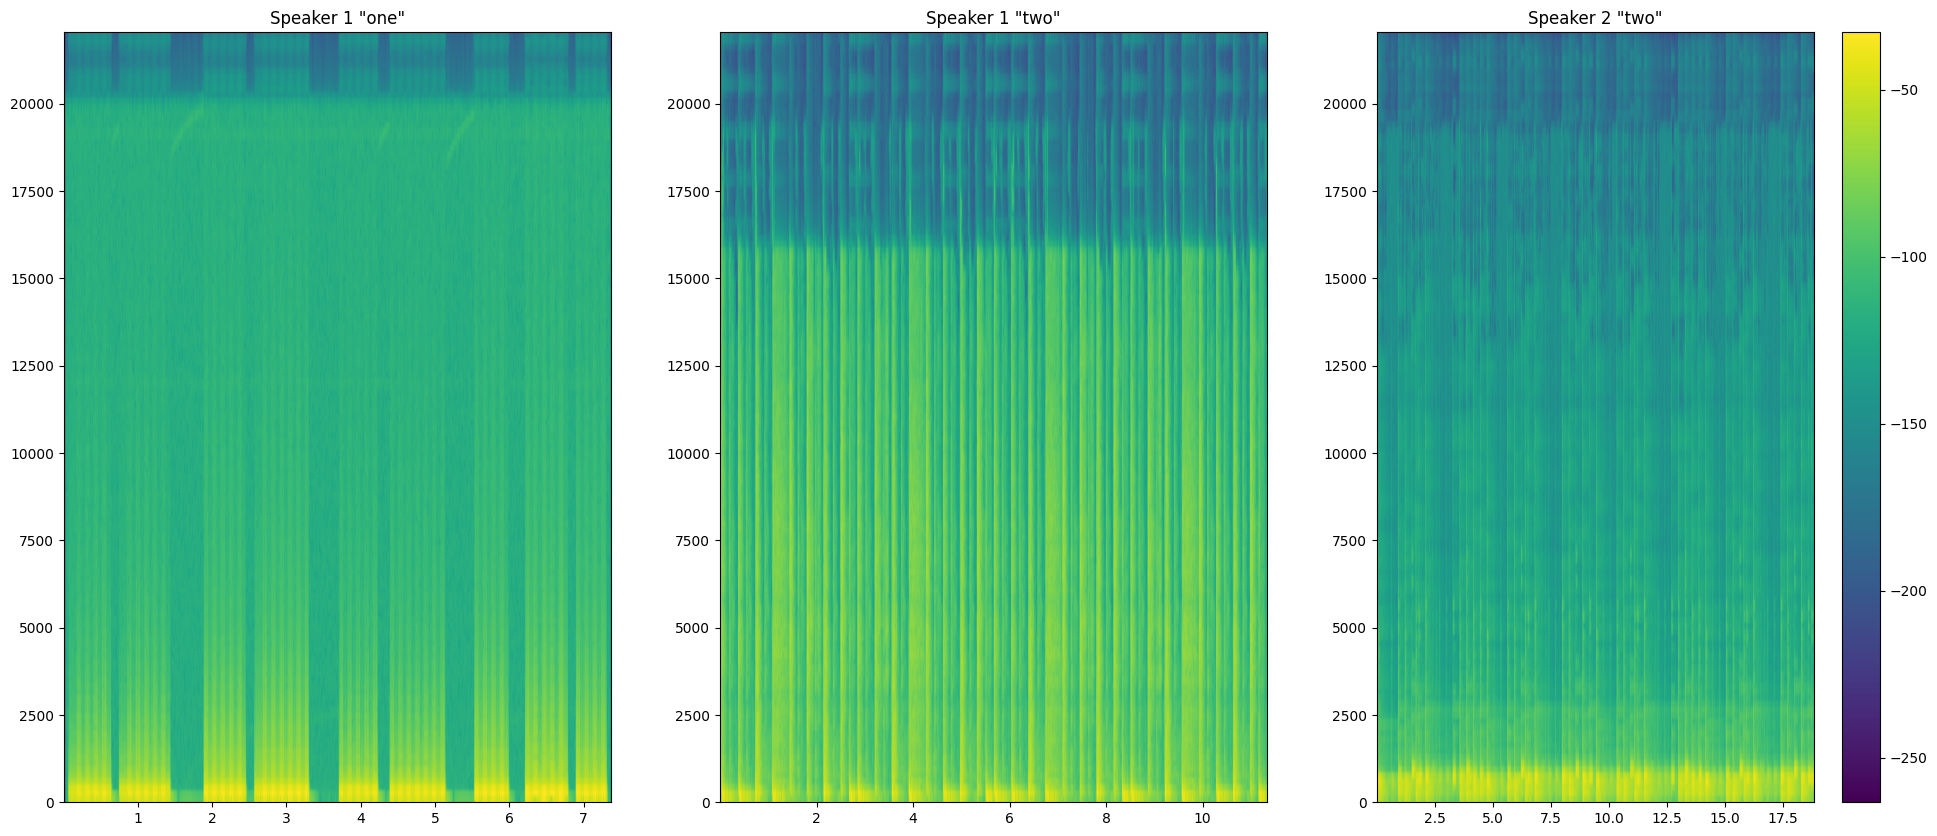

In [ ]:

plt.subplot(1, 3, 1)
plt.title('Speaker 1 "one"')
Pxx, freqs, bins, im = plt.specgram(data1, Fs=Fs)

plt.subplot(1, 3, 2)
plt.title('Speaker 1 "two"')
Pxx, freqs, bins, im = plt.specgram(data2_1, Fs=Fs)

plt.subplot(1, 3, 3)
plt.title('Speaker 2 "two"')
Pxx, freqs, bins, im = plt.specgram(data2_2, Fs=Fs)

plt.colorbar()
plt.show()

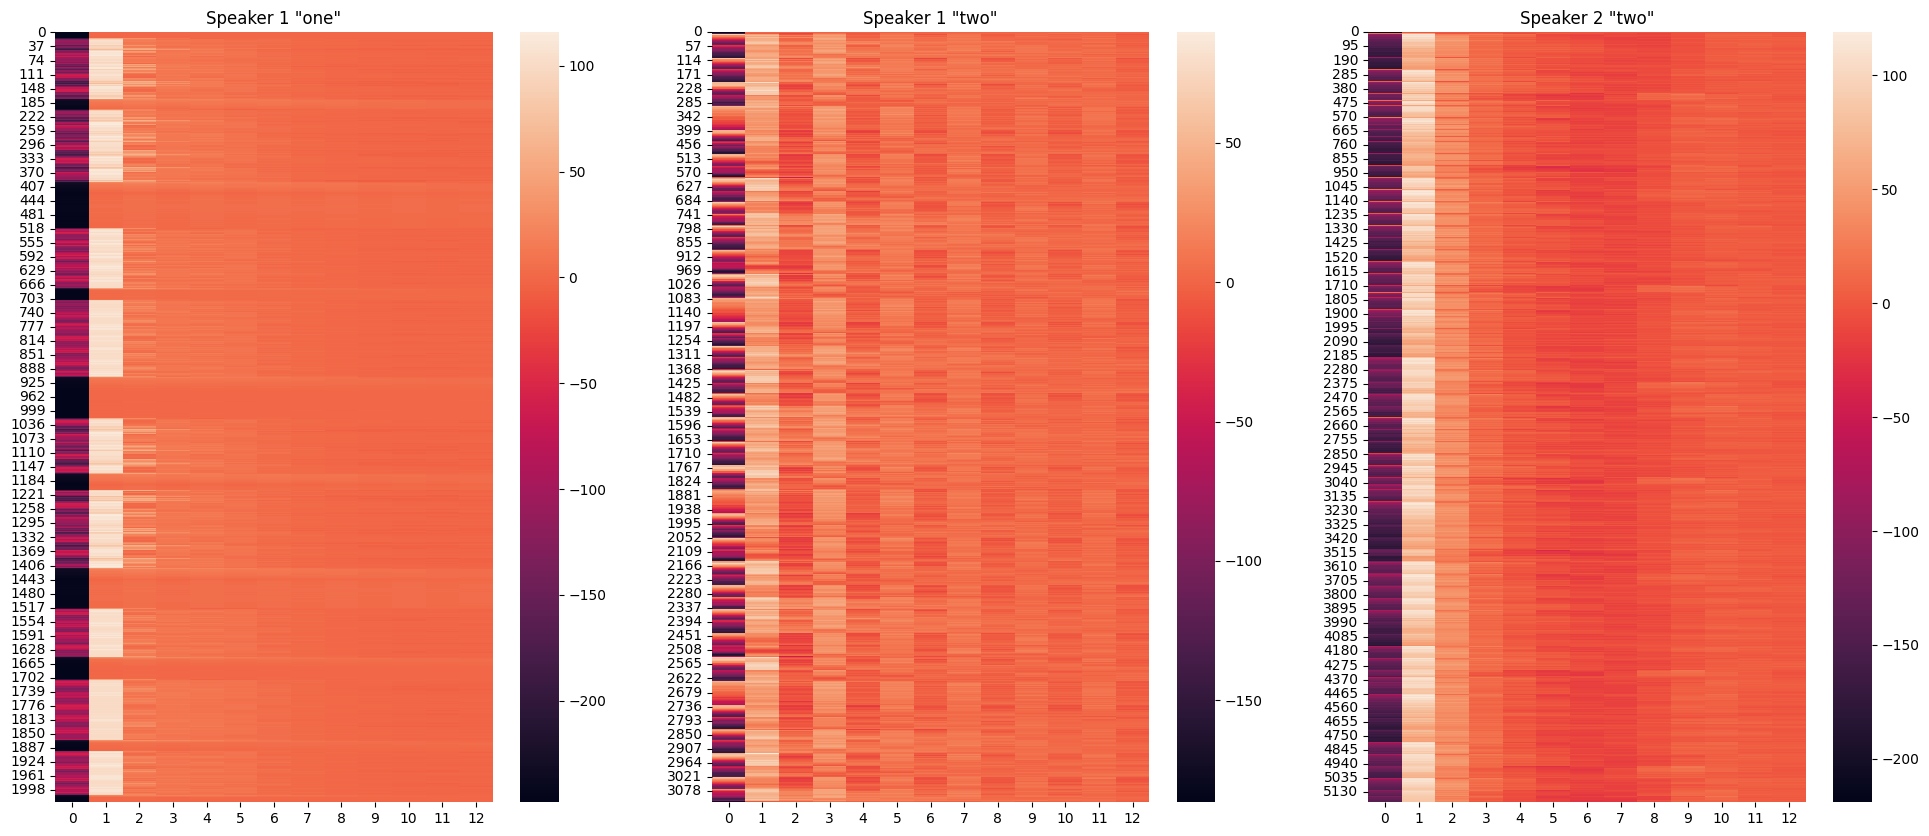

In [ ]:
import torch
import torchaudio.transforms as T
import seaborn as sns
import matplotlib.pyplot as plt

mfcc_transform = T.MFCC(
    sample_rate=Fs,
    n_mfcc=13,
    melkwargs={"n_fft": 400, "hop_length": 160, "n_mels": 23}
)

def plot_mfcc(data, ax, speaker, word):
    waveform = torch.from_numpy(data).float()
    if waveform.ndim == 1:
        waveform = waveform.unsqueeze(0)

    feats = mfcc_transform(waveform).squeeze(0).numpy().T

    sns.heatmap(feats, ax=ax)
    ax.set_title(f'Speaker {speaker} "{word}"')

fig, (ax1, ax2, ax3) = plt.subplots(ncols=3, figsize=(24, 10))
plot_mfcc(data1, ax1, 1, 'one')
plot_mfcc(data2_1, ax2, 1, 'two')  
plot_mfcc(data2_2, ax3, 2, 'two')
plt.show()

In [ ]:
from IPython.display import Audio
from scipy.io.wavfile import read
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import scale

from kaldi.feat.mfcc import Mfcc, MfccOptions
from kaldi.matrix import Vector

plt.rcParams['figure.figsize'] = (24, 10)

Fs, data1 = read('.wav')
Fs, data2_1 = read('Audio/recordings_2_jackson_1.wav')
Fs, data2_2 = read('Audio/recordings_2_george_29.wav')

print(f'sampling rate: {Fs}')
print(f'speaker 1 audio shape: {data2_1.shape}')

def plot_sound(data, axs, speaker, word):
    axs[0].plot(data)
    axs[0].set_ylabel('Amplitude')
    axs[0].set_xlabel('time')
    axs[0].set_title(f'Original Wave / Speaker {speaker} word "{word}"')
    axs[1].semilogy(np.abs(np.fft.fft(data)))
    axs[1].set_ylabel('$| F(wave)|$')
    axs[1].set_xlabel('frequency')
    axs[1].set_title(f'Fourier transform / Speaker {speaker} word "{word}"')

fig, axs = plt.subplots(nrows=2, ncols=3)
plot_sound(data1, axs[:, 0], 1, 'one')
plot_sound(data2_1, axs[:, 1], 2, 'two')
plot_sound(data2_2, axs[:, 2], 2, 'two')
plt.tight_layout()
plt.show()

plt.figure(figsize=(24, 10))

plt.subplot(1, 3, 1)
plt.title('Speaker 1 "one"')
Pxx, freqs, bins, im = plt.specgram(data1, Fs=Fs)

plt.subplot(1, 3, 2)
plt.title('Speaker 1 "two"')
Pxx, freqs, bins, im = plt.specgram(data2_1, Fs=Fs)

plt.subplot(1, 3, 3)
plt.title('Speaker 2 "two"')
Pxx, freqs, bins, im = plt.specgram(data2_2, Fs=Fs)

plt.colorbar()
plt.tight_layout()
plt.show()

mfcc_opts = MfccOptions()
mfcc_opts.frame_opts.samp_freq = float(Fs)
mfcc = Mfcc(mfcc_opts)

def plot_mfcc(data, ax, speaker, word):
    feats = mfcc.compute(Vector(data), 1.0)
    sns.heatmap(scale(feats), ax=ax)
    ax.set_title(f'Speaker {speaker} "{word}"')

fig, (ax1, ax2, ax3) = plt.subplots(ncols=3)
plot_mfcc(data1, ax1, 1, 'one')
plot_mfcc(data2_1, ax2, 1, 'two')
plot_mfcc(data2_2, ax3, 2, 'two')
plt.tight_layout()
plt.show()